Import Required Libraries

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix

Load the Breast Cancer Dataset

In [33]:
# load the dataset

data = load_breast_cancer()

X = pd.DataFrame(
    data.data,
    columns=data.feature_names
)

y = pd.Series(
    (data.target == 0).astype(int),
    name="malignant"
)

print(y.value_counts())

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Class names:", data.target_names)

malignant
0    357
1    212
Name: count, dtype: int64
Feature matrix shape: (569, 30)
Target shape: (569,)
Class names: ['malignant' 'benign']


Examine the Class Distribution

In [34]:
# examine the class distribution

class_counts = y.value_counts().sort_index()

class_distribution = pd.DataFrame({
    "Class": data.target_names,
    "count": class_counts.values,
    "Probability": class_counts.values / len(y)
})

print(class_distribution)

       Class  count  Probability
0  malignant    357     0.627417
1     benign    212     0.372583


Prepare Class Distribution for Plotting

In [35]:
class_distribution = y.value_counts().reset_index()

class_distribution.columns = ["Class", "Count"]

Visualize Class Distribution

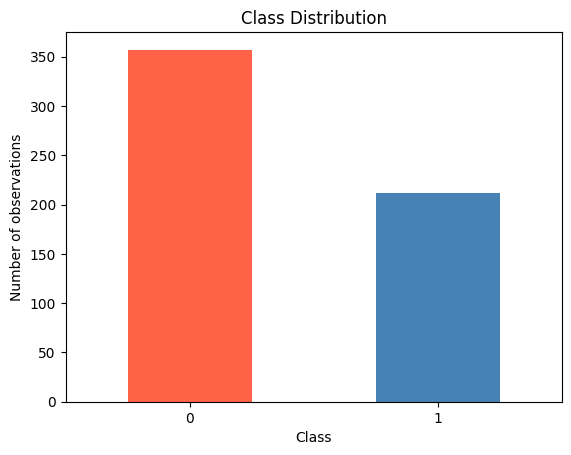

In [36]:
class_distribution.plot(
    x="Class",
    y="Count",
    kind="bar",
    legend=False,
    color=["tomato", "steelblue"]
)

plt.ylabel("Number of observations")

plt.title("Class Distribution")

plt.xticks(rotation=0)

plt.show()

Visualize Class Distribution as a Pie Chart

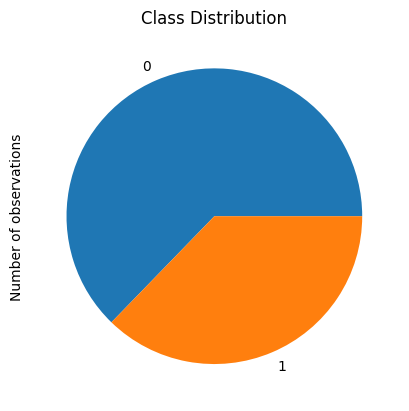

In [37]:
class_distribution.plot(
    x="Class",
    y="Count",
    kind="pie",
    legend=False,
    color=["tomato", "steelblue"]
)

plt.ylabel("Number of observations")

plt.title("Class Distribution")

plt.xticks(rotation=0)

plt.show()

Split the Dataset into Training and Testing Sets

In [38]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training size:", len(y_train))

print("Testing size:", len(y_test))

print("\n Training proportions:")

print(y_train.value_counts(normalize=True).sort_index())

print("\n Testing proportions:")

print(y_test.value_counts(normalize=True).sort_index())

Training size: 455
Testing size: 114

 Training proportions:
malignant
0    0.626374
1    0.373626
Name: proportion, dtype: float64

 Testing proportions:
malignant
0    0.631579
1    0.368421
Name: proportion, dtype: float64


Create and Train the Logistic Regression Model

In [39]:
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

model.fit(X_train, y_train)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression', LogisticRegression(max_iter=1000))])

Obtain Predicted Probabilities

In [40]:
#obtain predicted probabilities

probabilities = model.predict_proba(X_test)

print(probabilities[:5])

[[9.99635432e-01 3.64568116e-04]
 [1.07465986e-08 9.99999989e-01]
 [9.57432053e-01 4.25679471e-02]
 [4.23812678e-01 5.76187322e-01]
 [4.90844511e-01 5.09155489e-01]]


Create Prediction Results DataFrame

In [41]:
results = pd.DataFrame({
    "Actual_class": y_test.values,
    "P_malignant": probabilities[:, 0],
    "P_benign": probabilities[:, 1]
})

print(results.head(10))

   Actual_class   P_malignant  P_benign
0             0  9.996354e-01  0.000365
1             1  1.074660e-08  1.000000
2             0  9.574321e-01  0.042568
3             1  4.238127e-01  0.576187
4             0  4.908445e-01  0.509155
5             0  9.993840e-01  0.000616
6             1  2.384659e-01  0.761534
7             0  9.989878e-01  0.001012
8             0  9.994313e-01  0.000569
9             0  9.892324e-01  0.010768


Map Actual Classes to Labels  and  Display Actual Labels and Probabilities

In [42]:
results["Actual_label"] = results["Actual_class"].map({
    0: "Malignant",
    1: "Benign"
})

print(
    results[
        ["Actual_label", "P_malignant", "P_benign"]
    ].head(10)
)

  Actual_label   P_malignant  P_benign
0    Malignant  9.996354e-01  0.000365
1       Benign  1.074660e-08  1.000000
2    Malignant  9.574321e-01  0.042568
3       Benign  4.238127e-01  0.576187
4    Malignant  4.908445e-01  0.509155
5    Malignant  9.993840e-01  0.000616
6       Benign  2.384659e-01  0.761534
7    Malignant  9.989878e-01  0.001012
8    Malignant  9.994313e-01  0.000569
9    Malignant  9.892324e-01  0.010768


In [43]:
results = pd.DataFrame({
    "Actual_class": y_test.values,
    "P_malignant": probabilities[:, 0],
    "P_benign": probabilities[:, 1]
})

Apply Classification Threshold

In [44]:
threshold = 0.50

results["Predicted_malignant"] = (
    results["P_malignant"] >= threshold
).astype(int)

results["Predicted_label"] = results[
    "Predicted_malignant"
].map({
    1: "Malignant",
    0: "Benign"
})

print(
    results[
        ["Actual_class", "P_malignant", "Predicted_label"]
    ].head(10)
)

   Actual_class   P_malignant Predicted_label
0             0  9.996354e-01       Malignant
1             1  1.074660e-08          Benign
2             0  9.574321e-01       Malignant
3             1  4.238127e-01          Benign
4             0  4.908445e-01          Benign
5             0  9.993840e-01       Malignant
6             1  2.384659e-01          Benign
7             0  9.989878e-01       Malignant
8             0  9.994313e-01       Malignant
9             0  9.892324e-01       Malignant


Compare Different Thresholds

In [45]:
# Compare different thresholds

for threshold in [0.30, 0.50, 0.70]:
    predictions = (
        results["P_malignant"] >= threshold
    ).astype(int)

    print(
        f"Threshold = {threshold}: "
        f"Predicted malignant cases = {predictions.sum()}"
    )

Threshold = 0.3: Predicted malignant cases = 76
Threshold = 0.5: Predicted malignant cases = 74
Threshold = 0.7: Predicted malignant cases = 72


Construct Confusion Matrix

In [46]:
# Construct a confusion matrix

actual_malignant = (y_test.values == 0).astype(int)

for threshold in [0.30, 0.50, 0.70]:
    predicted_malignant = (
        probabilities[:, 0] >= threshold
    ).astype(int)

    cm = confusion_matrix(
        actual_malignant,
        predicted_malignant
    )

    print(f"\nThreshold = {threshold}")
    print(cm)


Threshold = 0.3
[[38  4]
 [ 0 72]]

Threshold = 0.5
[[39  3]
 [ 1 71]]

Threshold = 0.7
[[41  1]
 [ 1 71]]


Verify Accuracy Using Scikit-learn

In [47]:
# Predict malignant if probability >= threshold

y_pred = (
    results["P_malignant"] >= threshold
).astype(int)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print(
    "Sklearn accuracy:",
    accuracy_score(y_test, y_pred)
)

Sklearn accuracy: 0.017543859649122806


Calculate Metrics Across Thresholds

In [48]:
thresholds = [0.1, 0.3, 0.5, 0.7, 0.9]

threshold_metrics = []

for threshold in thresholds:

    y_pred = (
        results["P_malignant"] >= threshold
    ).astype(int)

    # Confusion Matrix
    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred
    ).ravel()

    # Metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    specificity = tn / (tn + fp)
    f1 = f1_score(y_test, y_pred)

    threshold_metrics.append({
        "Threshold": threshold,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Accuracy": accuracy,
        "Precision": precision,
        "Sensitivity_Recall": recall,
        "Specificity": specificity,
        "F1_Score": f1
    })

threshold_metrics = pd.DataFrame(threshold_metrics)

print(threshold_metrics.round(3))

   Threshold  TN  FP  FN  TP  Accuracy  Precision  Sensitivity_Recall  \
0        0.1   0  72  33   9     0.079      0.111               0.214   
1        0.3   0  72  38   4     0.035      0.053               0.095   
2        0.5   1  71  39   3     0.035      0.041               0.071   
3        0.7   1  71  41   1     0.018      0.014               0.024   
4        0.9   5  67  41   1     0.053      0.015               0.024   

   Specificity  F1_Score  
0        0.000     0.146  
1        0.000     0.068  
2        0.014     0.052  
3        0.014     0.018  
4        0.069     0.018  


In [49]:
metrics_data = []
thresholds = [0.1, 0.3, 0.5, 0.7, 0.9] #we need to check for all these thresholds

for threshold in thresholds:
    predicted_malignant = (
        probabilities[:, 0] >= threshold # 0 is M and 1 is B, so if p of 0 > threshold then its pred M
    ).astype(int)

    cm = confusion_matrix(
        actual_malignant.tolist(),
        predicted_malignant.tolist()
    )
    tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0,0,0,0) # convert into 1d array and handle cases where confusion matrix might not be 2x2

    accuracy = accuracy_score(actual_malignant, predicted_malignant)
    precision = precision_score(actual_malignant, predicted_malignant, zero_division=0)
    recall = recall_score(actual_malignant, predicted_malignant, zero_division=0)
    f1 = f1_score(actual_malignant, predicted_malignant, zero_division=0)

    metrics_data.append({
        'Threshold': threshold,
        'TN': tn,
        'FP': fp,
        'FN': fn,
        'TP': tp,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1
    })

metrics_df = pd.DataFrame(metrics_data)
display(metrics_df.round(3))

,Threshold,TN,FP,FN,TP,Accuracy,Precision,Recall,F1-Score
0,0.1,33,9,0,72,0.921,0.889,1.000,0.941
1,0.3,38,4,0,72,0.965,0.947,1.000,0.973
2,0.5,39,3,1,71,0.965,0.959,0.986,0.973
3,0.7,41,1,1,71,0.982,0.986,0.986,0.986
4,0.9,41,1,5,67,0.947,0.985,0.931,0.957
